**Classification (Multi-Class): Iris Dataset**

**Let's predict the species of an iris flower based on
its measurements like:**

**sepal length, sepal width, petal length, petal width**

In [45]:
# Load the Dataset

from sklearn.datasets import load_iris
import pandas as pd

iris = load_iris()
X, y = iris.data, iris.target

print(iris.feature_names)
print(iris.target_names)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
['setosa' 'versicolor' 'virginica']


In [46]:
# Split the Data

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=.2, random_state=1
)

In [47]:
X_train[:10]

array([[6.1, 3. , 4.6, 1.4],
       [7.7, 3. , 6.1, 2.3],
       [5.6, 2.5, 3.9, 1.1],
       [6.4, 2.8, 5.6, 2.1],
       [5.8, 2.8, 5.1, 2.4],
       [5.3, 3.7, 1.5, 0.2],
       [5.5, 2.3, 4. , 1.3],
       [5.2, 3.4, 1.4, 0.2],
       [6.5, 2.8, 4.6, 1.5],
       [6.7, 2.5, 5.8, 1.8]])

In [48]:
y_train[:10]

array([1, 2, 1, 2, 2, 0, 1, 0, 1, 2])

In [49]:
for i, value in enumerate(iris.target_names):
    print(i, value)

0 setosa
1 versicolor
2 virginica


In [50]:
# Train a Classifier. Let's use a Logistic Regression

from sklearn.linear_model import LogisticRegression
clf_model = LogisticRegression(max_iter=200)
clf_model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,200
,multi_class,'deprecated'


In [51]:
# Evaluate the Classifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

y_pred = clf_model.predict(X_test)

In [52]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9666666666666667


In [53]:
print(y_pred)
print(y_test)

[0 1 1 0 2 1 2 0 0 2 1 0 2 1 1 0 1 1 0 0 1 1 2 0 2 1 0 0 1 2]
[0 1 1 0 2 1 2 0 0 2 1 0 2 1 1 0 1 1 0 0 1 1 1 0 2 1 0 0 1 2]


In [54]:
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       1.00      0.92      0.96        13
           2       0.86      1.00      0.92         6

    accuracy                           0.97        30
   macro avg       0.95      0.97      0.96        30
weighted avg       0.97      0.97      0.97        30



In [55]:
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))


Confusion Matrix:
 [[11  0  0]
 [ 0 12  1]
 [ 0  0  6]]


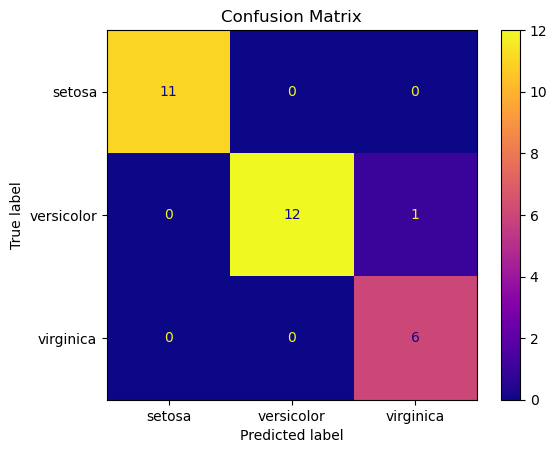

In [56]:
import matplotlib.pyplot as plt

cm_display = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=iris.target_names)
cm_display.plot(cmap=plt.cm.plasma)
plt.title('Confusion Matrix')
# plt.colorbar()
plt.show()

**Creating a Prediction Function**

**Let build a function that:**

- Accepts 4 flower measurements
- Predicts the species name

In [57]:
def predict_flower(sepal_length, sepal_width, petal_length, petal_width):
    sample = [[sepal_length, sepal_width, petal_length, petal_width]]
    # Predict
    pred = clf_model.predict(sample)[0]
    species = iris.target_names
    prediction = f'The specie of flower is {species[pred]}'
    return prediction

In [58]:
print(predict_flower(5.1, 3.5, 1.4, 0.2))

The specie of flower is setosa


In [59]:
print(predict_flower(6.0, 3.0, 4.8, 1.8))

The specie of flower is virginica


In [60]:
clf_model.predict([[5.1, 3.5, 1.4, 0.2]])

array([0])

In [61]:
# FEATURE ENGINEERING

X = iris.data
y = iris.target

In [62]:
from sklearn.feature_selection import SelectKBest, chi2

Selector = SelectKBest(score_func=chi2, k=4)
X_selected = Selector.fit(X, y)

In [68]:
import pandas as pd
#from sklearn.datasets import load_iris
from sklearn.feature_selection import SelectKBest, f_classif

iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target

selector = SelectKBest(score_func=chi2, k=2)
X_selected = selector.fit_transform(X, y)

FeatureScores = pd.DataFrame({
    'Specs': X.columns,
    'Scores': selector.scores_
})
print(FeatureScores.nlargest(4, 'Scores'))

               Specs      Scores
2  petal length (cm)  116.312613
3   petal width (cm)   67.048360
0  sepal length (cm)   10.817821
1   sepal width (cm)    3.710728


In [69]:
X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [71]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

model = LogisticRegression()
model.fit(X_train_selected, y_train)
print(f"Accuracy of model with selected features: {model.score(X_test_selected, y_test)}")

Accuracy of model with selected features: 1.0
